# ML Lab 5
### Name : Pranjal Chaubey
### Roll NO: 1
### Batch : A-A1

In [3]:
import pandas as pd
import numpy as np


In [4]:
df = pd.read_csv("/content/diabetes (6) - diabetes (6).csv")

In [5]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [7]:
df.shape

(768, 9)

In [8]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [9]:
df.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [11]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [12]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split,GridSearchCV,cross_val_score,StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report)

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style = "whitegrid")

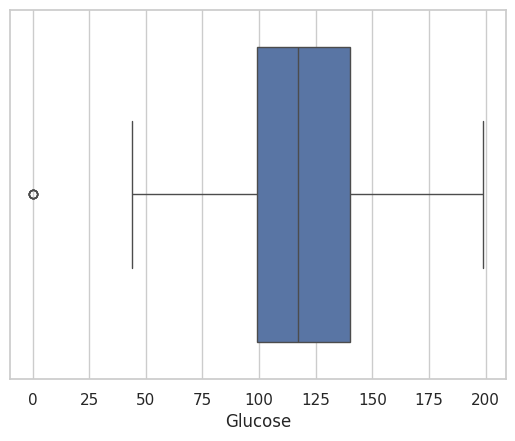

In [14]:
sns.boxplot(x=df["Glucose"])
plt.show()

In [15]:
zero_columns = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
zero_counts = (df[zero_columns]==0).sum()

print("Zero values : ")
print(zero_counts)

Zero values : 
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [16]:
df_clean = df.copy()
df_clean[zero_columns] = df_clean[zero_columns].replace(0,np.nan)

print("Missing values after replacing invalid zeros : ")
print(df_clean.isnull().sum())

Missing values after replacing invalid zeros : 
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [17]:
for col in zero_columns:
  df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Missing values after median imputation : ")
print(df_clean.isnull().sum())

Missing values after median imputation : 
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [18]:
x = df_clean.drop("Outcome",axis=1)
y = df_clean["Outcome"]

print("X shape:",x.shape)
print("Y shape:", y.shape)

X shape: (768, 8)
Y shape: (768,)


In [19]:
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

print("X_train shape:",X_train.shape[0])
print("X_test shape:",X_test.shape[0])
print("y_train shape:",y_train.shape)
print("y_test shape:",y_test.shape)

X_train shape: 614
X_test shape: 154
y_train shape: (614,)
y_test shape: (154,)


In [20]:
print("Training distribution : ")
print(y_train.value_counts(normalize = True))

print("Testing distribution : ")
print(y_test.value_counts(normalize=True))

Training distribution : 
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64
Testing distribution : 
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [21]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
scaler.fit_transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [23]:
scaler.transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [24]:
comparision = pd.DataFrame({
    "Original Mean" : X_train.mean(),
    "Original Std" : X_train.std(),
    "Scaled Mean" : X_train_scaled.mean(),
    "Scaled Std" : X_train_scaled.std()
})
display(comparision)

,Original Mean,Original Std,Scaled Mean,Scaled Std
Pregnancies,3.819218,3.314148,-1.566789e-16,1.0
Glucose,121.671010,30.003794,-1.566789e-16,1.0
BloodPressure,72.140065,12.275119,-1.566789e-16,1.0
SkinThickness,29.042345,8.891855,-1.566789e-16,1.0
Insulin,137.705212,78.764767,-1.566789e-16,1.0
BMI,32.446743,6.824142,-1.566789e-16,1.0
DiabetesPedigreeFunction,0.477428,0.330300,-1.566789e-16,1.0
Age,33.366450,11.833438,-1.566789e-16,1.0


In [25]:
k = 5

In [26]:
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train_scaled,y_train)

KNeighborsClassifier()

In [27]:
y_pred = knn.predict(X_test_scaled)
print("Predictions:")
print(y_pred[:20])

Predictions:
[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0]


In [28]:
y_prob = knn.predict_proba(X_test_scaled)
print("Probabilities:")
print(y_prob[:20])

Probabilities:
[[0.4 0.6]
 [0.8 0.2]
 [0.8 0.2]
 [0.4 0.6]
 [1.  0. ]
 [0.8 0.2]
 [0.8 0.2]
 [0.2 0.8]
 [1.  0. ]
 [0.4 0.6]
 [0.6 0.4]
 [0.4 0.6]
 [1.  0. ]
 [1.  0. ]
 [1.  0. ]
 [0.4 0.6]
 [0.2 0.8]
 [1.  0. ]
 [0.  1. ]
 [0.8 0.2]]


In [29]:
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)

Accuracy: 0.7532467532467533


In [30]:
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)

print("Precision:",precision)
print("Recall:",recall)
print("F1 Score:",f1)

Precision: 0.66
Recall: 0.6111111111111112
F1 Score: 0.6346153846153846


In [31]:
print(classification_report(y_test,y_pred,target_names=["No Diabetes","Diabetes"]))

              precision    recall  f1-score   support

 No Diabetes       0.80      0.83      0.81       100
    Diabetes       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



In [32]:
cm = confusion_matrix(y_test,y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[83 17]
 [21 33]]


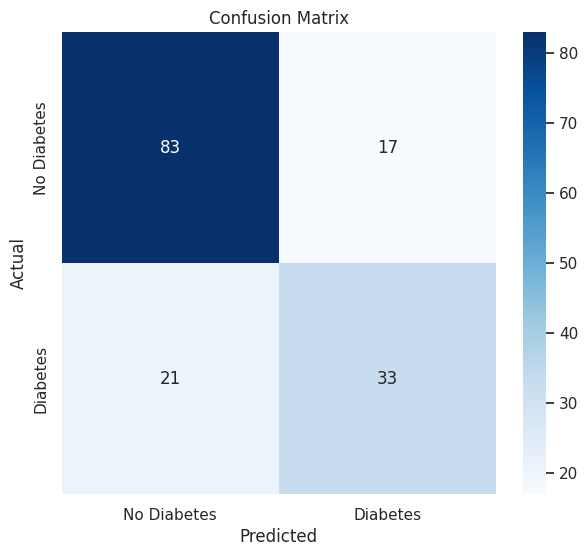

In [33]:
plt.figure(figsize=(7,6))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["No Diabetes","Diabetes"],yticklabels=["No Diabetes","Diabetes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [34]:
k_values = range(1,31)

train_accuracy = []
test_accuracy = []

for k in k_values:
  model = KNeighborsClassifier(n_neighbors=k)
  model.fit(X_train_scaled,y_train)
  train_accuracy.append(model.score(X_train_scaled,y_train))
  test_accuracy.append(model.score(X_test_scaled,y_test))

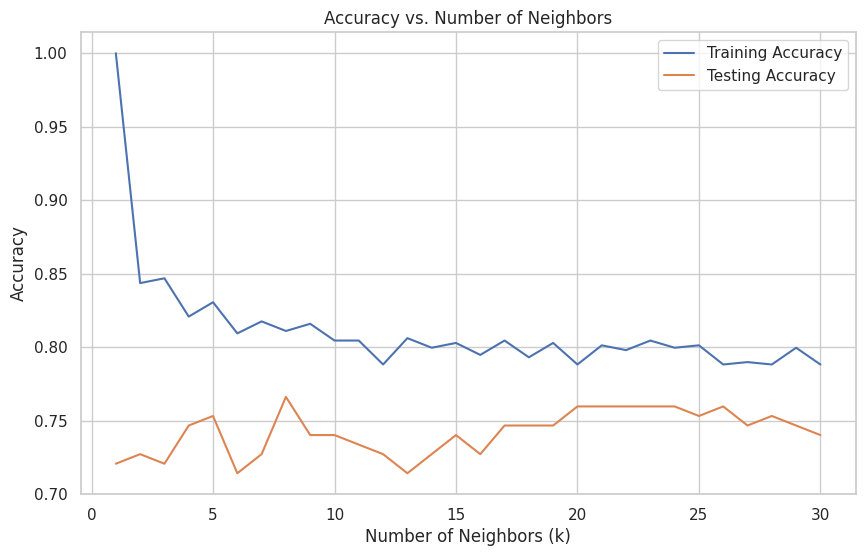

In [35]:
plt.figure(figsize=(10,6))
plt.plot(k_values,train_accuracy,label="Training Accuracy")
plt.plot(k_values,test_accuracy,label="Testing Accuracy")

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. Number of Neighbors")
plt.legend()
plt.show()

In [36]:
best_K_accuracy = k_values[np.argmax(test_accuracy)]
best_accuracy = max(test_accuracy)
print("Best K value:",best_K_accuracy)
print("Best Accuracy:",best_accuracy)

Best K value: 8
Best Accuracy: 0.7662337662337663


In [37]:
cv = StratifiedKFold(n_splits=10,shuffle=True,random_state=42)
cv_scores = []

for k in range(1,31):
  model = KNeighborsClassifier(n_neighbors=k)
  scores = cross_val_score(model,X_train_scaled,y_train,cv=cv,scoring="accuracy")
  cv_scores.append(scores.mean())

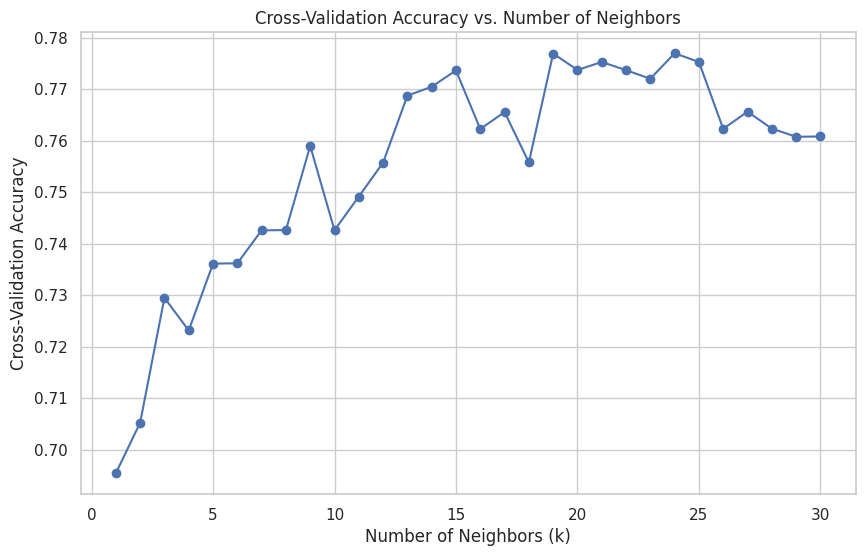

In [38]:
plt.figure(figsize=(10,6))
plt.plot(range(1,31),cv_scores,marker="o")

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Cross-Validation Accuracy")
plt.title("Cross-Validation Accuracy vs. Number of Neighbors")
plt.show()

In [39]:
best_K_cv = np.argmax(cv_scores) + 1

print("Best K value based on CV:",best_K_cv)
print("Best CV Accuracy:",max(cv_scores))

Best K value based on CV: 24
Best CV Accuracy: 0.776969857218403


In [40]:
param_grid = {"n_neighbors" : list(range(3,31,2)),"weights" : ["uniform","distance"],
              "metric" : ["euclidean","manhattan","minkowski"],
              "p" : [1,2]}


In [41]:
grid_search = GridSearchCV(KNeighborsClassifier(),param_grid,cv=5,scoring="accuracy",n_jobs=-1)
grid_search.fit(X_train_scaled,y_train)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'metric': ['euclidean', 'manhattan', 'minkowski'],
                         'n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23,
                                         25, 27, 29],
                         'p': [1, 2], 'weights': ['uniform', 'distance']},
             scoring='accuracy')

In [42]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'metric': 'euclidean', 'n_neighbors': 19, 'p': 1, 'weights': 'uniform'}
0.7769025723044115


In [43]:
best_knn = grid_search.best_estimator_

print(best_knn)

KNeighborsClassifier(metric='euclidean', n_neighbors=19, p=1)


In [44]:
final_pred = best_knn.predict(X_test_scaled)
final_prob = best_knn.predict_proba(X_test_scaled)[:,1]
